<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE SAMPLE TIME HAS CHANGED</h2>
<p style="margin:4px 0;"><b>The phonon sample period is 0.8 &micro;s (1.25 MHz), not 1.6 &micro;s (625 kHz).</b> A 4096-sample trace is 3.2768 ms. Until 2026-10-22 this notebook used 1.6 &micro;s, which was wrong.</p>
<p style="margin:4px 0;">What this means: times and energies are <b>half</b> of what older versions showed, frequencies are <b>doubled</b>. The time windows in this notebook (in &micro;s or ms) were halved so that they still cover the same samples, so the selection of events and every number counted in samples or counts is unchanged; the absorbed energies are half of what the earlier version printed.</p>
<p style="margin:4px 0;">This notebook was re-run with the new value (the library default, <code>PulseConfig</code> without <code>sample_period_s</code>). See <i>The sample period</i> in <code>python/README.md</code>.</p>
</div>

<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE CHANNEL MAP HAS CHANGED</h2>
<p style="margin:4px 0;">The dump's twelve board inputs are now mapped for the <b>Side-2 readout</b> of this series (<code>python/pulse_channels.py</code>, pull request 112): <b>six of them are sensors, all on Side 2</b> (DCRC1 pA, pB, pD = Side2pC, Side2pF, Side2pE; DCRC3 pA, pB, pD = Side2pB, Side2pA, Side2pD), DCRC4 pA is the <b>trigger input of the NaI array</b> (not a sensor) and the other five inputs are not connected. The old map used the wrong column of the Setup table. New names of the dump channels: (0, 3) was Side1pF, now Side2pE; (1, 0) was Side1pE, now Side2pB; (1, 1) was Side1pB, now Side2pA; (1, 3) was Side2pE, now Side2pD; (2, 0) was Side2pB, now the NaI input; (0, 0) Side2pC and (0, 1) Side2pF are as before.</p>
<p style="margin:4px 0;"><b>What changed in this notebook:</b> the working channels are the <b>six sensors</b>, not the seven channels whose signal changes: the NaI trigger input (DCRC4 pA, baseline about 7950 counts, no pulse) no longer enters the largest rise height, the quiet-pretrigger ratio or the plots; the tiles are labelled with the new names (the blank tiles are the NaI input and the five free inputs) and coloured by readout board instead of by side; the printed table lists six channels. <b>The selection is unchanged:</b> the same 48 events (53 without the quiet-pretrigger cut, the same five removed: 11024, 11052, 11060, 11076, 11460) and the same quiet-pretrigger numbers (928 of 1008 randoms, 489 of 509 real triggers), because the NaI input never had the largest rise height of a selected event.</p>
<p style="margin:4px 0;">Everything keyed by <code>(detector, channel)</code> (the cuts, the counts) is unchanged; names, groupings and plots are not. This notebook was re-run with the new map.</p>
</div>

# Small physics triggers in series 07221203_2025, dump 1

**Goal.** Find real (pulse) triggers with a *small* pulse height, as the starting point for normalising our pulses to TES current (see the note on pulse normalization). We take one dump, series `07221203_2025`, dump 1 (`07221203_2025_F0001`), and for every event measure the pulse height in every working channel. Then we histogram the **largest pulse height over all channels** of each event and choose the small-amplitude end.

**Trigger labels are swapped.** In this dump's `.csv` the label `Physics` marks the random triggers and `Unknown` marks the real (pulse) triggers; `pulse_cuts.randoms` and `pulse_cuts.real_triggers` encode this (a working assumption, see Note 2a). So "physics triggers" in the physical sense are the events labelled `Unknown`.

**Pulse height.** The first try used `pulse_quantities.max_deviation`, the largest |sample - pretrigger mean| after the 500-sample pretrigger window. It fails for small pulses: traces with a steep baseline drift have a large maximum deviation although they carry no pulse (the same problem as in Note 5), so the selection was mostly drift. Here we use a **drift-robust rise height** (section 2): fit a straight line to the pretrigger window (ending 75 us before the trigger, because the pulses start to rise before it), extend it over the first 200 samples (160 us) after the trigger, and take the largest *smoothed* excess above that line in that window. A drift continues along the line and gives no excess; a pulse rises at the trigger and does.

In [1]:
import sys
import warnings
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))
sys.path.insert(0, str(Path.cwd().resolve()))      # this notebook's folder, for small_triggers.py

import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
import pulse_channels as pch
from pulse_config import PulseConfig

import check_environment
check_environment.check()

import small_triggers as st      # the two-sided baseline of sections 4 to 6

warnings.filterwarnings("once")
FIGDIR = Path("..") / "figures"     # the figures folder of the R76 notebooks
FIGDIR.mkdir(exist_ok=True)

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


## 1. Load the dump and the trigger labels

In [2]:
DUMP = "07221203_2025_F0001"          # series 07221203_2025, dump 1
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]
ROLE = {(c.detector, c.channel): c.role for c in pch.all_channels()}      # sensor, nai_trigger or not_connected (Side-2 readout)

trigger_types = pio.trigger_types(cdms, det_ids[0])
real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers
rand = pc.randoms(trigger_types)             # label 'Physics': the random triggers
print(f"{len(trigger_types)} events: {rand.sum()} randoms (label 'Physics'), {real.sum()} real triggers (label 'Unknown')")

1517 events: 1008 randoms (label 'Physics'), 509 real triggers (label 'Unknown')


C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\3390795884.py:6: UserWarning: all_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  ROLE = {(c.detector, c.channel): c.role for c in pch.all_channels()}      # sensor, nai_trigger or not_connected (Side-2 readout)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\3390795884.py:9: UserWarning: real_triggers is marked under_development: the other half of the randoms assumption: events recorded as 'Unknown' are taken to be real (pulse-triggered) events. Not confirmed; see `randoms`
  real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers
C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\3390795884.py:10: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: event

## 2. Pulse height of every event in every channel

Of the twelve board inputs, six are **sensors** (Side-2 readout, see `pulse_channels`: Side2pA to Side2pF). The other six are not channels of the detector: DCRC4 pA is the trigger input of the NaI array (its baseline is about 7950 counts and it carries no pulse in this dump) and five inputs are not connected (they read 0). The six sensors are the working channels.

**The drift-robust rise height.** For each trace: (1) fit a straight line to the pretrigger samples, after the first 10 glitch samples and up to 75 us (94 samples) before the trigger, because the pulses start to rise up to about 40 us before it and would otherwise tilt the line; (2) in the 200 samples after the trigger (samples 500 to 700) subtract that line, extended; (3) smooth with an 8-sample moving average to suppress the sample-to-sample noise; (4) the rise height is the largest value of the result. Unlike `max_deviation` it is signed (our pulses go up) and it only looks at the window where a pulse starts. The old `max_deviation` is kept alongside for comparison.

For the noise of each channel we use the spread of the rise height over the randoms (1.4826 times the median absolute deviation, which ignores the randoms that carry a pulse).

In [3]:
PRE_END, WIN, SMOOTH = config_500.pretrigger_samples, 200, 8   # trigger sample, window after the trigger, smoothing (samples)
FIT_END = PRE_END - 94      # the line is fitted up to here: 75 us (94 samples) before the trigger, because the pulses start to rise up to ~40 us before it

def rise_height(pulses, config=config_500, window=WIN, smooth=SMOOTH):
    """Drift-robust pulse height: largest smoothed excess above the extended pretrigger line, in the first `window` samples after the trigger (counts)."""
    pulses = np.asarray(pulses, dtype=float)
    start, g = config.pretrigger_samples, config.glitch_samples
    x_pre = np.arange(g, FIT_END)
    slope, intercept = np.polyfit(x_pre, pulses[:, g:FIT_END].T, 1)           # one line per trace
    x_win = np.arange(start, start + window + smooth - 1)
    resid = pulses[:, x_win] - (slope[:, None] * x_win + intercept[:, None])
    csum = np.cumsum(np.pad(resid, ((0, 0), (1, 0))), axis=1)
    smoothed = (csum[:, smooth:] - csum[:, :-smooth]) / smooth                # moving average, `window` values per trace
    return smoothed.max(axis=1)

pre_rms = {}      # (det, ch) -> RMS of the pretrigger residual about the fitted line, of every event, counts
amp = {}          # (det, ch) -> rise height of every event, counts
dev = {}          # (det, ch) -> max_deviation of every event, counts (the first try)
noise = {}        # (det, ch) -> noise of the rise height, from the randoms, counts
others = []       # the inputs that are not sensors: the NaI trigger input and the free inputs
for key in KEYS:
    if ROLE[key] != pch.SENSOR:
        others.append(key)
        continue
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    assert p.std(axis=1).max() > 0, f"sensor {pch.channel_name(*key)} never changes"
    amp[key] = rise_height(p)
    pre_rms[key] = st.pretrigger_residual_rms(p, config_500)
    dev[key] = pq.max_deviation(p, config_500)
    r = amp[key][rand]
    noise[key] = 1.4826 * np.median(np.abs(r - np.median(r)))
working = list(amp)
name = lambda key: pch.channel_name(*key)
print(f"{len(working)} sensor channels; not sensors: {', '.join(name(k) for k in others)}")
print(f"{'channel':<10}{'noise (counts)':>16}{'median height, randoms':>24}{'median, real triggers':>24}")
for key in working:
    print(f"{name(key):<10}{noise[key]:>16.2f}{np.median(amp[key][rand]):>24.1f}{np.median(amp[key][real]):>24.1f}")

A = np.array([amp[k] for k in working])                    # (channels, events)
amp_max = A.max(axis=0)                                    # largest rise height over the channels, per event
amp_max_sigma = (A / np.array([noise[k] for k in working])[:, None]).max(axis=0)   # same, in units of each channel's noise
max_channel = [working[i] for i in A.argmax(axis=0)]       # which channel carries the maximum, per event
dev_max = np.array([dev[k] for k in working]).max(axis=0)  # the first try, for comparison

6 sensor channels; not sensors: DCRC1pC, DCRC3pC, NaI, DCRC4pB, DCRC4pC, DCRC4pD
channel     noise (counts)  median height, randoms   median, real triggers
Side2pC               0.92                     1.7                   169.5
Side2pF               1.23                     2.0                   353.3
Side2pE               1.05                     1.8                   230.2
Side2pB               1.33                     3.1                   506.4
Side2pA               1.52                     2.8                   695.3
Side2pD               1.31                     2.6                   401.5


C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\3346741922.py:33: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)
C:\Users\villanoa\Research\NSDF-Data-pn2\python\pulse_channels.py:129: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return channel_info(detector, channel, readout).name


## 3. Histogram of the largest rise height over all channels

One entry per event. Real triggers (blue) and randoms (grey) on a logarithmic height axis. The dashed line is the real triggers' largest `max_deviation` (the first try); the difference between it and the blue line is the drift.

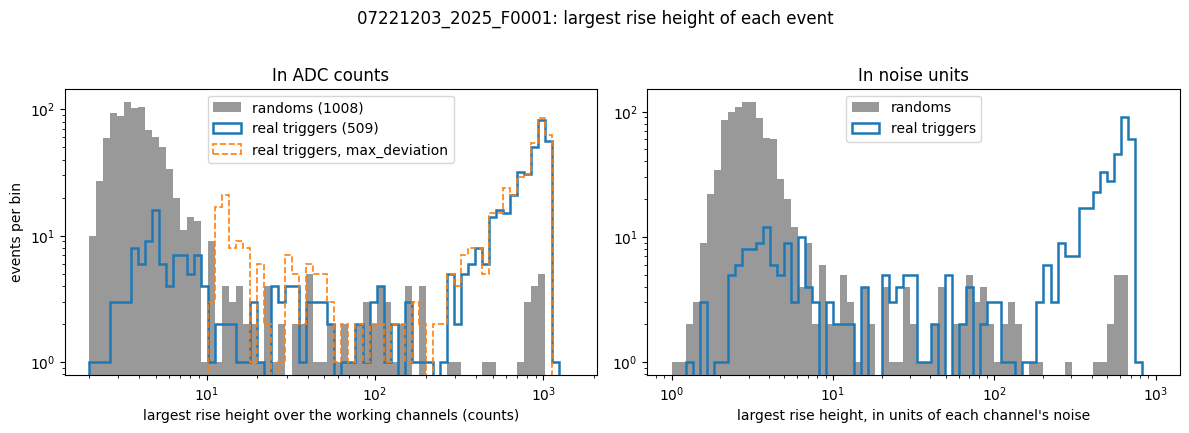

In [4]:
bins = np.logspace(np.log10(2), np.log10(1500), 70)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.hist(amp_max[rand], bins=bins, color="0.6", label=f"randoms ({rand.sum()})")
ax.hist(amp_max[real], bins=bins, histtype="step", linewidth=1.8, color="C0", label=f"real triggers ({real.sum()})")
ax.hist(dev_max[real], bins=bins, histtype="step", linewidth=1.2, linestyle="--", color="C1", label="real triggers, max_deviation")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("largest rise height over the working channels (counts)")
ax.set_ylabel("events per bin")
ax.set_title("In ADC counts")
ax.legend()

bins_s = np.logspace(np.log10(1), np.log10(1000), 70)
ax = axes[1]
ax.hist(amp_max_sigma[rand], bins=bins_s, color="0.6", label="randoms")
ax.hist(amp_max_sigma[real], bins=bins_s, histtype="step", linewidth=1.8, color="C0", label="real triggers")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("largest rise height, in units of each channel's noise")
ax.set_title("In noise units")
ax.legend()
fig.suptitle(f"{DUMP}: largest rise height of each event", y=1.02)
fig.tight_layout()
fig.savefig(FIGDIR / f"pulse-height-max-all-channels-{DUMP}.png", dpi=150, bbox_inches="tight")
plt.show()

## 3b. A quiet pretrigger

A real pulse should start at the trigger. Some events have another pulse, a step or a strong curvature already in the pretrigger window (event 11060 has a pulse of about 450 counts starting 175 us before the trigger). The rise height of such an event is meaningless and the baseline fitted there is spoiled.

**The quiet-pretrigger cut.** For each channel, the RMS of the residual about the fitted pretrigger line (over the samples the line is fitted to) is divided by the median of that RMS over the randoms, which sets the channel's normal level. An event is *quiet* if the **largest** of these ratios over the working channels is below `QUIET_PRE_MAX` (1.75, a little above the 90th percentile of the randoms, which is 1.5).

largest pretrigger ratio over the channels: randoms median 1.06, 90th percentile 1.50, 99th percentile 113
quiet pretrigger (ratio < 1.75): 928 of 1008 randoms, 489 of 509 real triggers


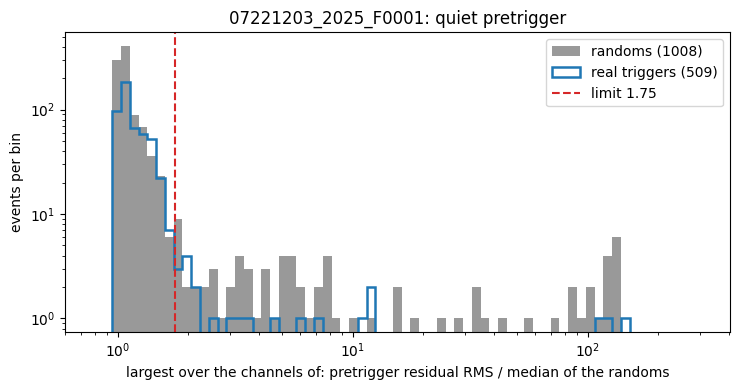

In [5]:
pre_ratio, quiet_pre = st.quiet_pretrigger(pre_rms, rand)
print(f"largest pretrigger ratio over the channels: randoms median {np.median(pre_ratio[rand]):.2f}, 90th percentile {np.percentile(pre_ratio[rand], 90):.2f}, 99th percentile {np.percentile(pre_ratio[rand], 99):.0f}")
print(f"quiet pretrigger (ratio < {st.QUIET_PRE_MAX}): {quiet_pre[rand].sum()} of {rand.sum()} randoms, {quiet_pre[real].sum()} of {real.sum()} real triggers")

bins_r = np.logspace(np.log10(0.8), np.log10(300), 70)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(pre_ratio[rand], bins=bins_r, color="0.6", label=f"randoms ({rand.sum()})")
ax.hist(pre_ratio[real], bins=bins_r, histtype="step", linewidth=1.8, color="C0", label=f"real triggers ({real.sum()})")
ax.axvline(st.QUIET_PRE_MAX, color="C3", linestyle="--", label=f"limit {st.QUIET_PRE_MAX}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("largest over the channels of: pretrigger residual RMS / median of the randoms")
ax.set_ylabel("events per bin")
ax.set_title(f"{DUMP}: quiet pretrigger")
ax.legend()
fig.tight_layout()
fig.savefig(FIGDIR / f"quiet-pretrigger-{DUMP}.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Select the small pulses

The choice of range is made by eye from the histogram above. Only events with a quiet pretrigger (section 3b) are kept. `AMP_LOW` must be well above the noise of the randoms (so the pulse is real); 15 counts is about three times the randoms' typical largest height over the six channels, and `AMP_HIGH` keeps only the small end. **These two numbers are provisional; edit them and rerun.**

In [6]:
AMP_LOW, AMP_HIGH = 15.0, 200.0           # counts: provisional range for 'small pulses'

p50, p90 = np.percentile(amp_max[rand], [50, 90])
print(f"for scale: the randoms' largest rise height over the channels has median {p50:.1f} and 90th percentile {p90:.1f} counts (the tail includes randoms that carry a pulse)")
small = real & quiet_pre & (amp_max >= AMP_LOW) & (amp_max < AMP_HIGH)
print(f"{small.sum()} of {real.sum()} real triggers have a quiet pretrigger and a largest rise height between {AMP_LOW:.0f} and {AMP_HIGH:.0f} counts")
print(f"({(real & (amp_max >= AMP_LOW) & (amp_max < AMP_HIGH)).sum()} without the quiet-pretrigger cut; removed: " + ", ".join(str(pio.event_id(det_ids[0][j])) for j in np.flatnonzero(real & ~quiet_pre & (amp_max >= AMP_LOW) & (amp_max < AMP_HIGH))) + ")")
chans, counts = np.unique([name(max_channel[i]) for i in np.flatnonzero(small)], return_counts=True)
print("channel with the largest rise height:", ", ".join(f"{c} {n}" for c, n in zip(chans, counts)))

for scale: the randoms' largest rise height over the channels has median 3.8 and 90th percentile 8.8 counts (the tail includes randoms that carry a pulse)
48 of 509 real triggers have a quiet pretrigger and a largest rise height between 15 and 200 counts
(53 without the quiet-pretrigger cut; removed: 11024, 11052, 11060, 11076, 11460)
channel with the largest rise height: Side2pA 19, Side2pB 1, Side2pD 7, Side2pE 1, Side2pF 20


C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\3346741922.py:33: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)


### The selected events

Traces of 12 selected events spread evenly through the selection (ordered by event number), in the channel that has the largest rise height of the event, with the baseline subtracted (a quadratic fitted before the pulse and in the late tail, see section 6, so a drift appears as a flat trace). The dashed line marks the trigger.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\3346741922.py:33: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)


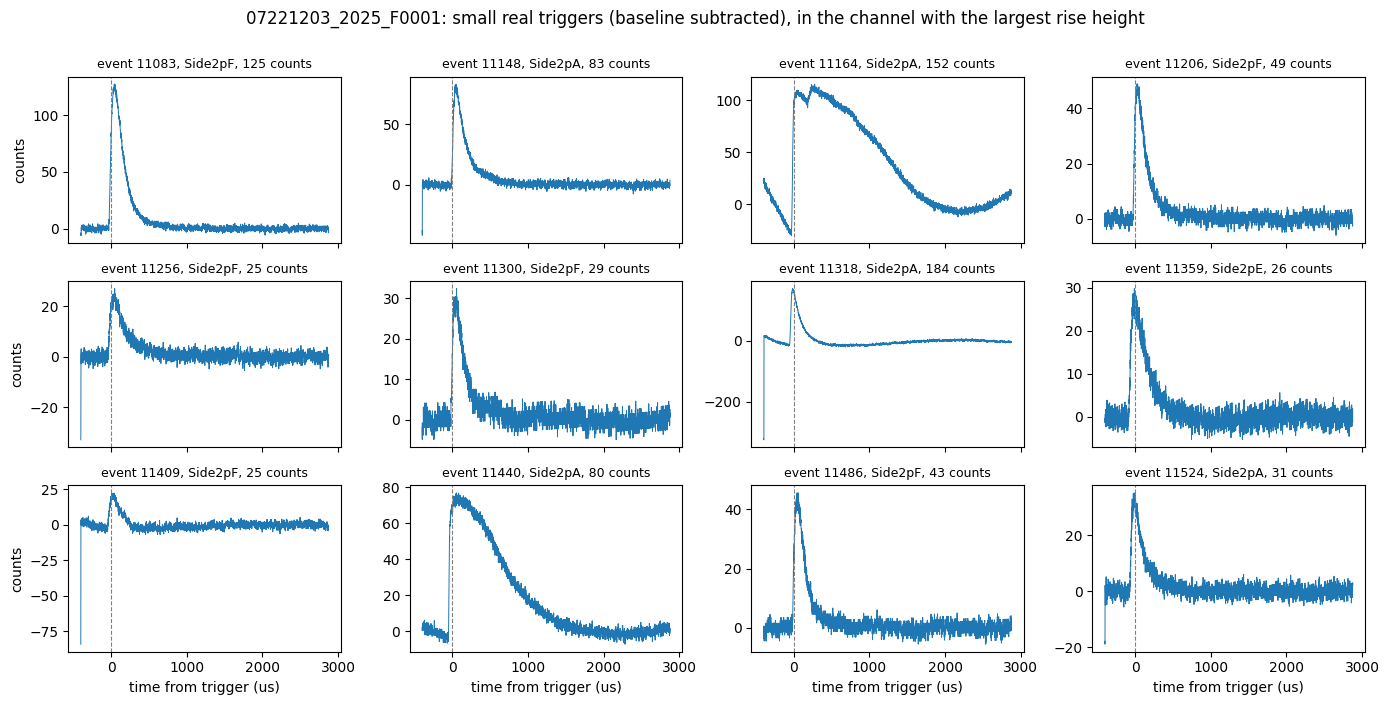

In [7]:
sel = np.flatnonzero(small)
idx = sel[np.linspace(0, len(sel) - 1, 12).astype(int)]
n_samples = 4096
t_us = (np.arange(n_samples) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
fig, axes = plt.subplots(3, 4, figsize=(14, 7), sharex=True)
for ax, i in zip(axes.flat, idx):
    key = max_channel[i]
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    ax.plot(t_us, st.subtract_baseline(p[i][None, :], config_500)[0], linewidth=0.7)
    ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
    ax.set_title(f"event {pio.event_id(det_ids[0][i])}, {name(key)}, {amp_max[i]:.0f} counts", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("time from trigger (us)")
for ax in axes[:, 0]:
    ax.set_ylabel("counts")
fig.suptitle(f"{DUMP}: small real triggers (baseline subtracted), in the channel with the largest rise height", y=1.0)
fig.tight_layout()
fig.savefig(FIGDIR / f"small-real-triggers-{DUMP}.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. A few selected events in all channels

For a few of the selected events, one figure each: one tile per channel (rows are the readout boards DCRC1, DCRC3 and DCRC4, columns the four channels of a board; the inputs that are not sensors, the NaI trigger input and the free inputs, are blank). The whole trace is drawn (from 400 us before the trigger to 2.9 ms after it; set `PLOT_US` to zoom in), **after the baseline is subtracted**: a quadratic is fitted to the pretrigger samples and to the late tail of the trace (the two grey bands; the pulse is left out) and subtracted from the whole trace, so a slow drift no longer hides the pulse. Section 6 compares this with a straight line fitted before the pulse only. The dashed line is the trigger. **All channels of an event share one vertical scale** (set by the largest pulse of the event), so the channels can be compared by eye; a slow drift far from the pulse can run off the edge. The events are spread evenly in height through the selection; to look at particular events, put their event numbers in `EVENTS`.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\225662779.py:52: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  ax.plot(t_us[show], flats[(det, ch)][show], linewidth=0.8, color=BOARD_COLOUR[pch.channel_info(det, ch).dcrc])
C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\225662779.py:53: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  ax.set_title(f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc}): {amp[(det, ch)][i]:.0f} counts", fontsize=9)


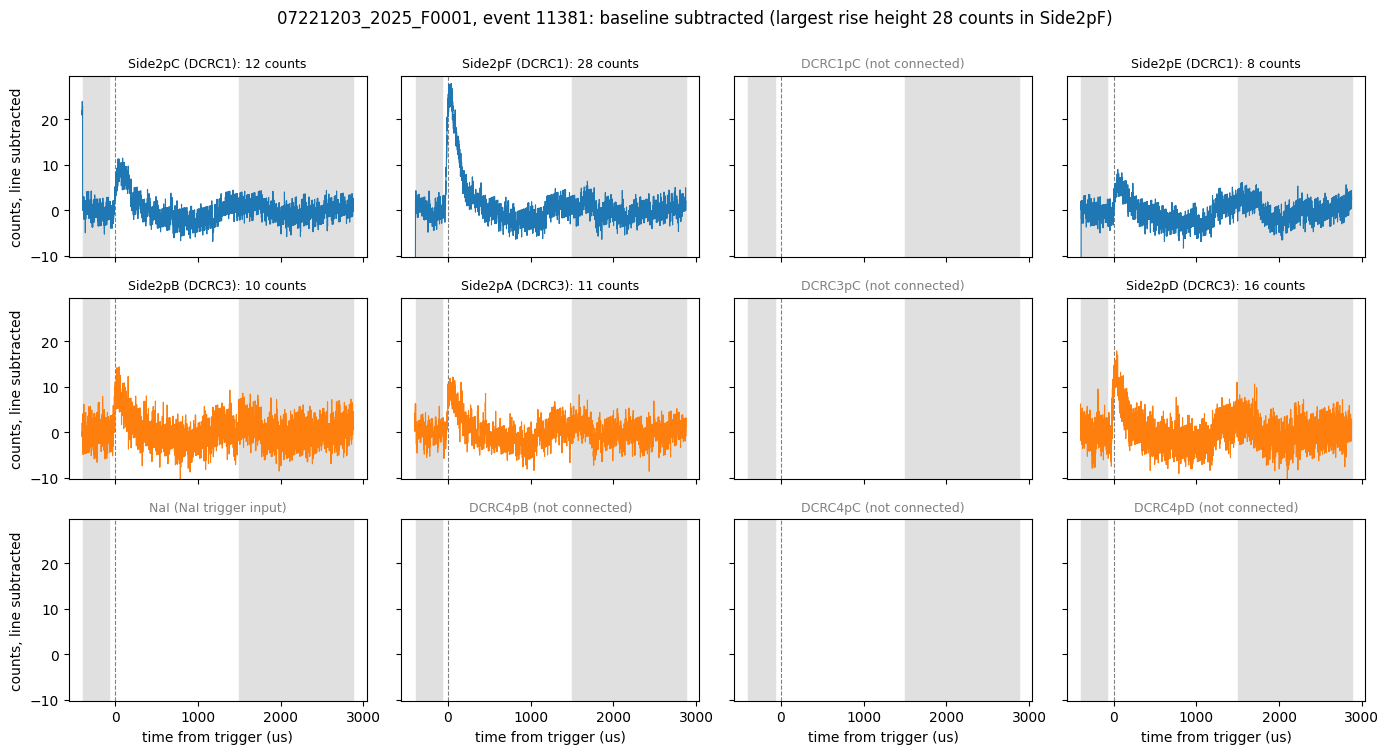

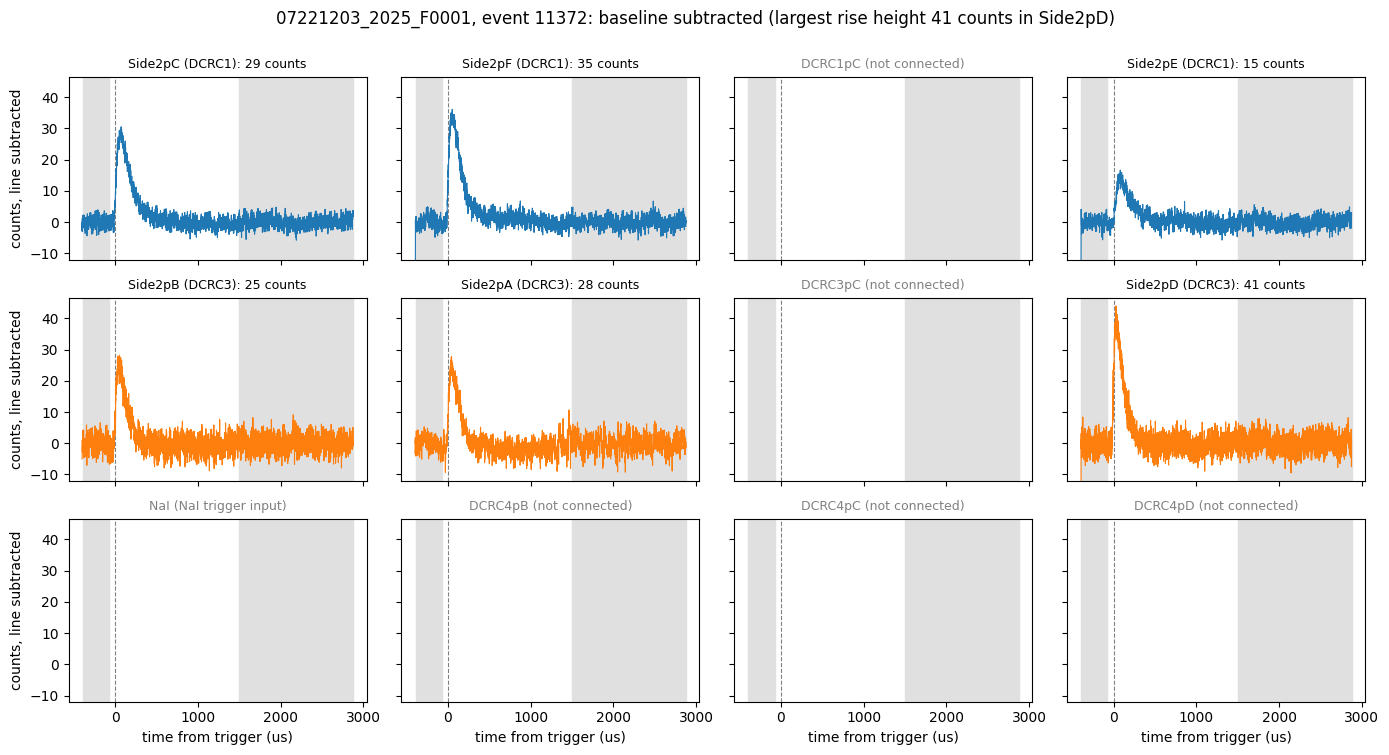

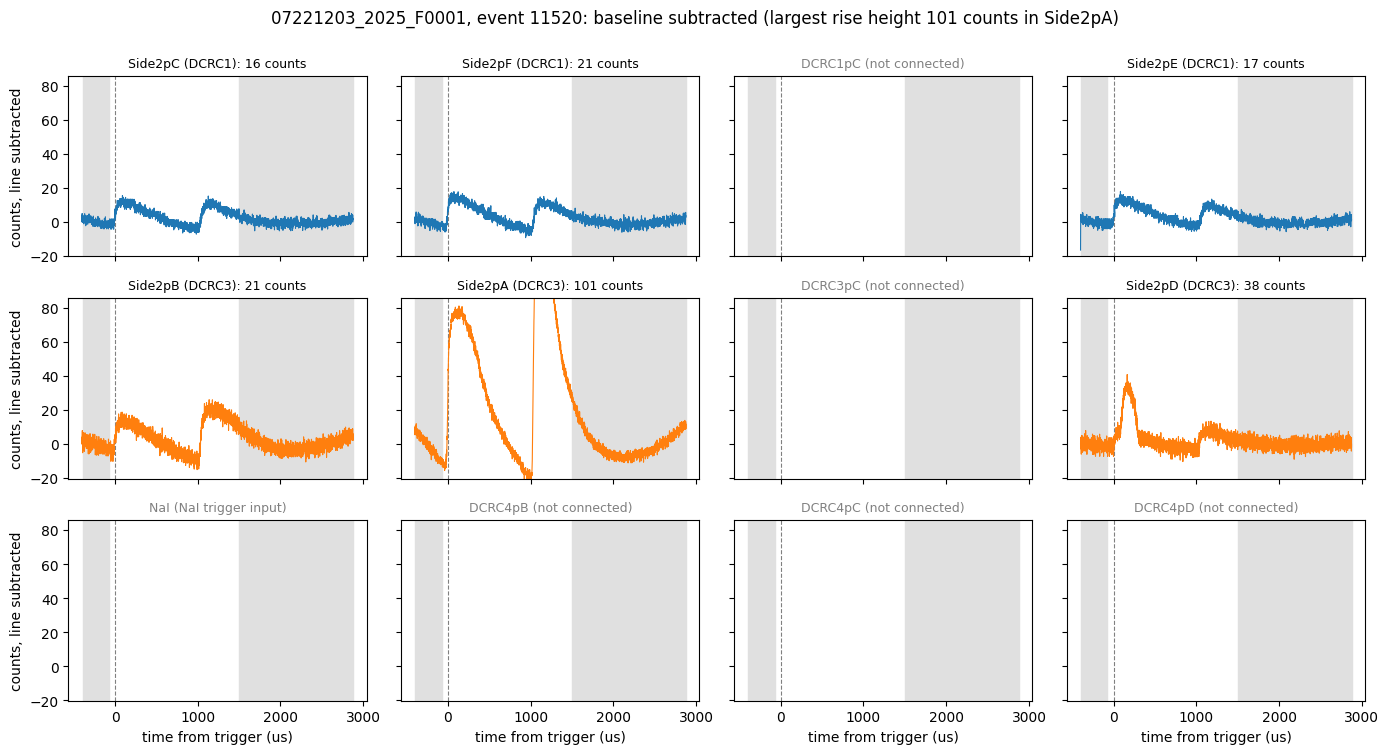

In [8]:
N_EVENTS = 3
EVENTS = None                      # or a list of event numbers, e.g. [11095, 11221]
BOARD_COLOUR = {"DCRC1": "C0", "DCRC3": "C1"}      # one colour per readout board
PLOT_US = None                     # None draws the whole trace; or a window in microseconds from the trigger, e.g. (-200, 750)

event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])
sel = np.flatnonzero(small)
if EVENTS is None:
    order = sel[np.argsort(amp_max[sel])]                                  # selected events, smallest height first
    chosen = order[np.linspace(0, len(order) - 1, N_EVENTS + 2).astype(int)[1:-1]]
else:
    chosen = np.array([np.flatnonzero(event_numbers == ev)[0] for ev in EVENTS])

def subtract_baseline(traces, config=config_500):
    """Subtract the two-sided baseline (small_triggers.two_sided_baseline: a quadratic fitted to the pretrigger samples and to the late tail,
    leaving the pulse out). Returns the traces and the baselines."""
    traces = np.asarray(traces, dtype=float)
    base = st.two_sided_baseline(traces, config)
    return traces - base, base

# the chosen events' traces in every channel (the inputs that are not sensors stay empty)
chosen_traces = {}
for key in KEYS:
    if key in others:
        continue
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    chosen_traces[key] = p[chosen]

n_samples = chosen_traces[working[0]].shape[-1]
t_us = (np.arange(n_samples) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
t_fit = (np.array([config_500.glitch_samples, FIT_END]) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
t_tail = (st.TAIL_FROM_US, t_us[-1])          # the late tail the baseline is also fitted to
show = np.ones_like(t_us, dtype=bool) if PLOT_US is None else (t_us >= PLOT_US[0]) & (t_us <= PLOT_US[1])

near_pulse = (t_us >= -200) & (t_us <= 750)      # the part of the trace that sets the vertical scale
for n, i in enumerate(chosen):
    flats = {key: subtract_baseline(chosen_traces[key][n][None, :])[0][0] for key in working}
    # one vertical scale for every channel of the event, set by the pulses (the window around the trigger);
    # a slow drift far from the pulse can leave the tile at the edges
    lo = min(f[near_pulse].min() for f in flats.values())
    hi = max(f[near_pulse].max() for f in flats.values())
    pad = 0.05 * (hi - lo)
    fig, axes = plt.subplots(3, 4, figsize=(14, 7.5), sharex=True, sharey=True)
    for (det, ch), ax in zip(KEYS, axes.flat):
        ax.axvspan(*t_fit, color="0.88", zorder=0)
        ax.axvspan(*t_tail, color="0.88", zorder=0)
        ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
        if (det, ch) in others:
            what = "NaI trigger input" if ROLE[(det, ch)] == pch.NAI_TRIGGER else "not connected"
            ax.set_title(f"{pch.channel_name(det, ch)} ({what})", fontsize=9, color="0.5")
            continue
        ax.plot(t_us[show], flats[(det, ch)][show], linewidth=0.8, color=BOARD_COLOUR[pch.channel_info(det, ch).dcrc])
        ax.set_title(f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc}): {amp[(det, ch)][i]:.0f} counts", fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel("time from trigger (us)")
    for ax in axes[:, 0]:
        ax.set_ylabel("counts, line subtracted")
    axes[0, 0].set_ylim(lo - pad, hi + pad)           # the shared vertical scale
    fig.suptitle(f"{DUMP}, event {event_numbers[i]}: baseline subtracted (largest rise height {amp_max[i]:.0f} counts in {name(max_channel[i])})", y=1.0)
    fig.tight_layout()
    fig.savefig(FIGDIR / f"small-trigger-event{event_numbers[i]}-all-channels-{DUMP}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 6. Which baseline? A straight line before the pulse, or a quadratic on both sides of it

The first plots subtracted a straight line fitted to the pretrigger samples and extended over the whole 3.3 ms trace. The drift is curved, so the line drifts away from the trace. The alternative (`small_triggers.two_sided_baseline`) fits a polynomial to the pretrigger samples **and** to the late tail (from 1.5 ms after the trigger), leaving the pulse out, and interpolates across the pulse.

Test, on the selected events in the working channels: the residual (trace minus baseline) in the **1 to 1.5 ms stretch**, which neither baseline was fitted to, so the line has to extrapolate and the polynomial to interpolate; and in the 1.5 to 2.9 ms tail, which the polynomial was fitted to (so only a measure of how well it follows the drift). Smaller is better; the noise floor of a channel is about 1 to 2 counts. The rise height still uses the straight pretrigger line, which only has to hold over the 160 us after the trigger.

In [9]:
sel = np.flatnonzero(small)
n_samples = 4096
gap = st.window(config_500, n_samples, 1000, 1500)
tail = st.window(config_500, n_samples, 1500, 1e9)
late = st.window(config_500, n_samples, 2500, 1e9)

res = {}      # key -> dict of residual traces of the selected events, per baseline
for key in working:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    P = p[sel].astype(float)
    res[key] = {"straight line, pretrigger only": P - st.pretrigger_line(P, config_500)}
    for order in (1, 2, 3):
        res[key][f"two-sided, order {order}"] = P - st.two_sided_baseline(P, config_500, order=order)
    res[key]["raw"] = P
methods = [m for m in res[working[0]] if m != "raw"]
rms = lambda r, w: np.sqrt((r[:, w] ** 2).mean(axis=1))
print(f"{'baseline':<34}{'median RMS 1-1.5 ms':>19}{'median RMS 1.5-2.9 ms':>21}{'median |mean| 2.5-2.9 ms':>24}")
for m in methods:
    g = np.concatenate([rms(res[k][m], gap) for k in working])
    t = np.concatenate([rms(res[k][m], tail) for k in working])
    l = np.concatenate([np.abs(res[k][m][:, late].mean(axis=1)) for k in working])
    print(f"{m:<34}{np.median(g):>19.2f}{np.median(t):>21.2f}{np.median(l):>24.2f}")
print()
print(f"{'channel':<10}{'noise (counts)':>16}{'RMS 1-1.5 ms, line':>20}{'RMS 1-1.5 ms, order 2':>22}")
for key in working:
    print(f"{name(key):<10}{noise[key]:>16.2f}{np.median(rms(res[key]['straight line, pretrigger only'], gap)):>20.2f}{np.median(rms(res[key]['two-sided, order 2'], gap)):>22.2f}")

baseline                          median RMS 1-1.5 msmedian RMS 1.5-2.9 msmedian |mean| 2.5-2.9 ms
straight line, pretrigger only                   4.49                 8.16                    9.42
two-sided, order 1                               2.55                 2.36                    0.47
two-sided, order 2                               2.35                 1.85                    0.12
two-sided, order 3                               2.37                 1.83                    0.09

channel     noise (counts)  RMS 1-1.5 ms, line RMS 1-1.5 ms, order 2
Side2pC               0.92                3.19                  1.55
Side2pF               1.23                3.53                  1.72
Side2pE               1.05                3.46                  1.64
Side2pB               1.33                6.98                  2.68
Side2pA               1.52                7.82                  2.25
Side2pD               1.31                4.59                  2.58


C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\3346741922.py:33: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)


### Examples

Three (event, channel) pairs from the selection, chosen by how much the quadratic helps in the 1 to 1.5 ms stretch: the largest improvement, the 75th percentile, the median. Top: the raw trace with both baselines (grey bands = where the quadratic was fitted). Bottom: the trace after subtracting each, on the same scale.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_21380\3346741922.py:33: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)


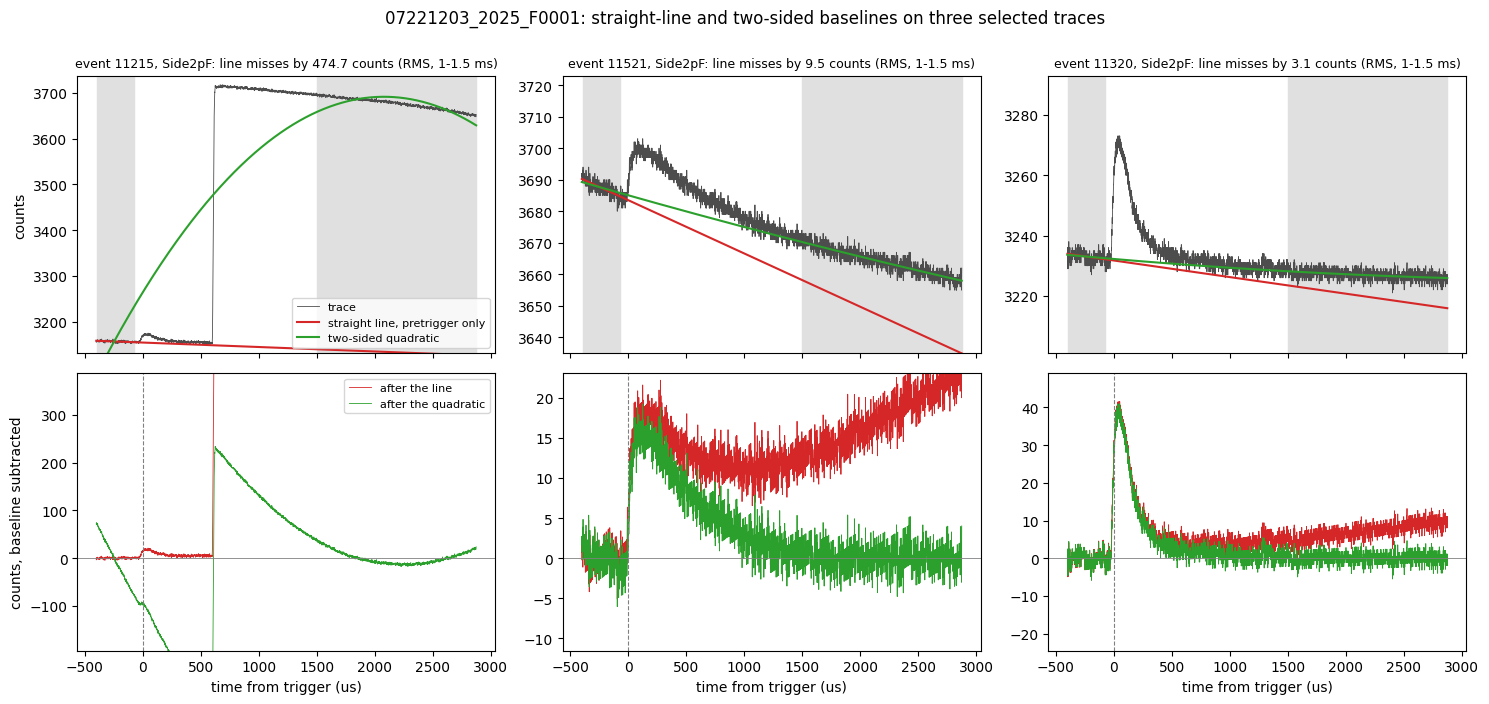

In [10]:
pairs = []     # (improvement, key, row in sel) for traces that carry a pulse of at least AMP_LOW in that channel
for key in working:
    gain = rms(res[key]["straight line, pretrigger only"], gap) - rms(res[key]["two-sided, order 2"], gap)
    for j, i in enumerate(sel):
        if amp[key][i] >= AMP_LOW:
            pairs.append((gain[j], key, j))
pairs.sort(key=lambda x: -x[0])
picks = [pairs[0], pairs[len(pairs) // 4], pairs[len(pairs) // 2]]

t_us = (np.arange(n_samples) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
t_fit = (np.array([config_500.glitch_samples, FIT_END]) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for col, (g, key, j) in enumerate(picks):
    raw = res[key]["raw"][j]
    base_line = st.pretrigger_line(raw[None, :], config_500)[0]
    base_two = st.two_sided_baseline(raw[None, :], config_500)[0]
    ax = axes[0, col]
    ax.axvspan(*t_fit, color="0.88", zorder=0); ax.axvspan(st.TAIL_FROM_US, t_us[-1], color="0.88", zorder=0)
    ax.plot(t_us, raw, color="0.3", linewidth=0.6, label="trace")
    ax.plot(t_us, base_line, color="C3", label="straight line, pretrigger only")
    ax.plot(t_us, base_two, color="C2", label="two-sided quadratic")
    ax.set_title(f"event {event_numbers[sel[j]]}, {name(key)}: line misses by {g:.1f} counts (RMS, 1-1.5 ms)", fontsize=9)
    ax.set_ylim(raw.min() - 20, raw.max() + 20)
    ax = axes[1, col]
    ax.plot(t_us, raw - base_line, color="C3", linewidth=0.6, label="after the line")
    ax.plot(t_us, raw - base_two, color="C2", linewidth=0.6, label="after the quadratic")
    ax.axhline(0, color="0.5", linewidth=0.6); ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
    ax.set_xlabel("time from trigger (us)")
    top = np.abs(raw - base_two)[(t_us > -200) & (t_us < 750)].max()
    ax.set_ylim(-0.6 * top, 1.2 * top)
axes[0, 0].legend(fontsize=8); axes[1, 0].legend(fontsize=8)
axes[0, 0].set_ylabel("counts"); axes[1, 0].set_ylabel("counts, baseline subtracted")
fig.suptitle(f"{DUMP}: straight-line and two-sided baselines on three selected traces", y=1.0)
fig.tight_layout()
fig.savefig(FIGDIR / f"baseline-comparison-{DUMP}.png", dpi=150, bbox_inches="tight")
plt.show()